# BÀI THỰC HÀNH SỐ 1 - KHAI PHÁ DỮ LIỆU
## PHẦN 2 - BÀI 2 (TRANG 37, 38): KHAI PHÁ LUẬT KẾT HỢP DỮ LIỆU ONLINE RETAIL
- **Họ và tên:** Bùi Minh Trọng
- **MSSV:** 6451071081
- **Lớp:** CQ.64.CNTT
- **Tập dữ liệu:** `Online Retail.xlsx`


### Câu 1: Đọc dữ liệu vào chương trình


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

print("Họ và tên: Bùi Minh Trọng - MSSV: 6451071081")

data_candidates = ['Online Retail.xlsx', '../Online Retail.xlsx', '../../TH1/Online Retail.xlsx', '../TH1/Online Retail.xlsx']
data_path = next((p for p in data_candidates if os.path.exists(p)), 'Online Retail.xlsx')
df_retail = pd.read_excel(data_path)

print(f"Kích thước tập dữ liệu: {df_retail.shape[0]:,} dòng x {df_retail.shape[1]} cột")
display(df_retail.head())
print("\nThông tin cấu trúc tập dữ liệu:")
print(df_retail.info())


Họ và tên: Bùi Minh Trọng - MSSV: 6451071081
Kích thước tập dữ liệu: 541,909 dòng x 8 cột


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Thông tin cấu trúc tập dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB
None


**Nhận xét Câu 1:**
- Tập dữ liệu bán lẻ trực tuyến có 541,909 dòng và 8 cột thuộc tính bao gồm: InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country.


### Câu 2: Tiền xử lý dữ liệu


In [2]:
print("Họ và tên: Bùi Minh Trọng - MSSV: 6451071081")

df_retail['Description'] = df_retail['Description'].astype(str).str.strip()
df_retail.dropna(subset=['InvoiceNo'], inplace=True)
df_retail['InvoiceNo'] = df_retail['InvoiceNo'].astype(str)

print(f"Số dòng sau khi xử lý missing InvoiceNo: {len(df_retail):,}")
display(df_retail.head())


Họ và tên: Bùi Minh Trọng - MSSV: 6451071081
Số dòng sau khi xử lý missing InvoiceNo: 541,909


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


**Nhận xét Câu 2:**
- Đã cắt bỏ khoảng trắng thừa ở cột Description, loại bỏ các dòng không có InvoiceNo và chuyển InvoiceNo sang kiểu chuỗi.


### Câu 3: Xóa bỏ các hóa đơn tín dụng (chứa chữ 'C')


In [3]:
print("Họ và tên: Bùi Minh Trọng - MSSV: 6451071081")

df_clean_retail = df_retail[~df_retail['InvoiceNo'].str.contains('C')].copy()

print(f"Số dòng trước khi xóa hóa đơn 'C': {len(df_retail):,}")
print(f"Số dòng sau khi xóa hóa đơn 'C': {len(df_clean_retail):,}")
print(f"Số lượng hóa đơn tín dụng đã loại bỏ: {len(df_retail) - len(df_clean_retail):,}")


Họ và tên: Bùi Minh Trọng - MSSV: 6451071081
Số dòng trước khi xóa hóa đơn 'C': 541,909
Số dòng sau khi xóa hóa đơn 'C': 532,621
Số lượng hóa đơn tín dụng đã loại bỏ: 9,288


**Nhận xét Câu 3:**
- Đã loại bỏ các giao dịch trả hàng/hủy đơn (hóa đơn tín dụng có chữ 'C') để phản ánh chính xác hành vi mua hàng thực tế.


### Câu 4: Thống kê số dòng dữ liệu theo từng quốc gia


Họ và tên: Bùi Minh Trọng - MSSV: 6451071081
Top 10 quốc gia có số lượng giao dịch nhiều nhất:


Country
United Kingdom    487622
Germany             9042
France              8408
EIRE                7894
Spain               2485
Netherlands         2363
Belgium             2031
Switzerland         1967
Portugal            1501
Australia           1185
Name: count, dtype: int64

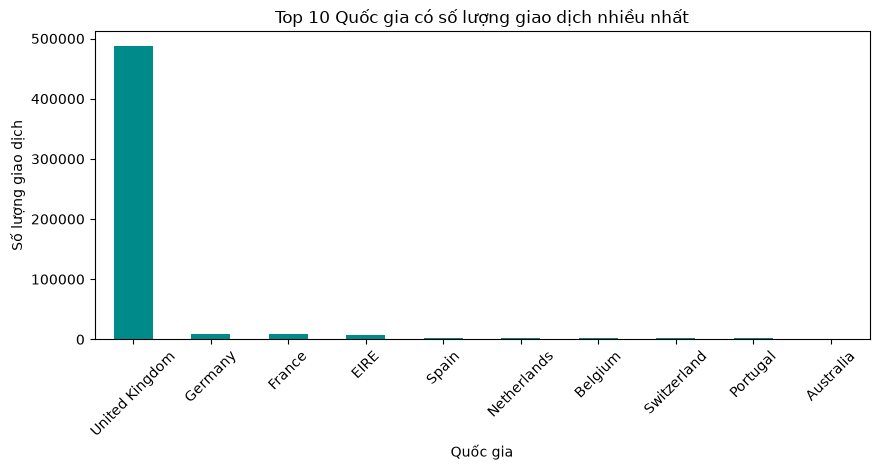

In [4]:
print("Họ và tên: Bùi Minh Trọng - MSSV: 6451071081")

country_counts = df_clean_retail['Country'].value_counts()
print("Top 10 quốc gia có số lượng giao dịch nhiều nhất:")
display(country_counts.head(10))

plt.figure(figsize=(10, 4))
country_counts.head(10).plot(kind='bar', color='darkcyan')
plt.title("Top 10 Quốc gia có số lượng giao dịch nhiều nhất")
plt.xlabel("Quốc gia")
plt.ylabel("Số lượng giao dịch")
plt.xticks(rotation=45)
plt.show()


**Nhận xét Câu 4:**
- Nước Anh (United Kingdom) chiếm số lượng giao dịch áp đảo (gần 90% tổng số giao dịch). Theo sau là Đức (Germany) và Pháp (France).


### Câu 5: Lọc hóa đơn từ United Kingdom và gom nhóm Quantity


In [ ]:
print("Họ và tên: Bùi Minh Trọng - MSSV: 6451071081")

basket_uk = (df_clean_retail[df_clean_retail['Country'] == 'United Kingdom']
             .groupby(['InvoiceNo', 'Description'])['Quantity']
             .sum().unstack().reset_index().fillna(0)
             .set_index('InvoiceNo'))

print("Kích thước ma trận giỏ hàng của United Kingdom:", basket_uk.shape)
display(basket_uk.iloc[:5, :5])


Họ và tên: Bùi Minh Trọng - MSSV: 6451071081
Kích thước ma trận giỏ hàng của United Kingdom: (18668, 4176)


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX
InvoiceNo,,,,,
536365,0.0,0.0,0.0,0.0,0.0
536366,0.0,0.0,0.0,0.0,0.0
536367,0.0,0.0,0.0,0.0,0.0
536368,0.0,0.0,0.0,0.0,0.0
536369,0.0,0.0,0.0,0.0,0.0


**Nhận xét Câu 5:**
- Đã tạo thành công ma trận giỏ hàng cho thị trường Anh: mỗi hàng là một hóa đơn, mỗi cột là một mặt hàng, giá trị là tổng số lượng mua.


### Câu 6: Chuyển sang One-Hot, loại bỏ POSTAGE, tìm tập phổ biến và luật kết hợp


In [6]:
print("Họ và tên: Bùi Minh Trọng - MSSV: 6451071081")

# Chuyển đổi sang One-Hot
basket_sets_uk = (basket_uk >= 1).astype(int)

# Xóa POSTAGE nếu có
if 'POSTAGE' in basket_sets_uk.columns:
    basket_sets_uk.drop('POSTAGE', inplace=True, axis=1)

from mlxtend.frequent_patterns import apriori, association_rules

frequent_itemsets = apriori(basket_sets_uk, min_support=0.03, use_colnames=True)
print(f"Số lượng tập phổ biến tìm được (min_sup = 3%): {len(frequent_itemsets)}")
display(frequent_itemsets.head(10))

rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)
print(f"\nSố lượng luật kết hợp tìm được (min_conf = 50%): {len(rules)}")
display(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10))


Họ và tên: Bùi Minh Trọng - MSSV: 6451071081


C:\Users\Bui Minh Trong\AppData\Roaming\Python\Python314\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


Số lượng tập phổ biến tìm được (min_sup = 3%): 131


,support,itemsets
0,0.045800,frozenset({6 RIBBONS RUSTIC CHARM})
1,0.031123,frozenset({60 CAKE CASES VINTAGE CHRISTMAS})
2,0.040336,frozenset({60 TEATIME FAIRY CAKE CASES})
3,0.046925,frozenset({ALARM CLOCK BAKELIKE GREEN})
4,0.035140,frozenset({ALARM CLOCK BAKELIKE PINK})
5,0.049818,frozenset({ALARM CLOCK BAKELIKE RED})
6,0.036212,frozenset({ANTIQUE SILVER T-LIGHT GLASS})
7,0.073441,frozenset({ASSORTED COLOUR BIRD ORNAMENT})
8,0.042265,frozenset({BAKING SET 9 PIECE RETROSPOT})
9,0.035087,frozenset({BATHROOM METAL SIGN})



Số lượng luật kết hợp tìm được (min_conf = 50%): 10


,antecedents,consequents,support,confidence,lift
0,frozenset({ALARM CLOCK BAKELIKE GREEN}),frozenset({ALARM CLOCK BAKELIKE RED}),0.030159,0.642694,12.900874
1,frozenset({ALARM CLOCK BAKELIKE RED}),frozenset({ALARM CLOCK BAKELIKE GREEN}),0.030159,0.605376,12.900874
2,frozenset({GREEN REGENCY TEACUP AND SAUCER}),frozenset({PINK REGENCY TEACUP AND SAUCER}),0.030909,0.617773,16.404818
3,frozenset({PINK REGENCY TEACUP AND SAUCER}),frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.030909,0.820768,16.404818
4,frozenset({GREEN REGENCY TEACUP AND SAUCER}),frozenset({ROSES REGENCY TEACUP AND SAUCER}),0.037551,0.750535,14.640537
5,frozenset({ROSES REGENCY TEACUP AND SAUCER}),frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.037551,0.732497,14.640537
6,frozenset({JUMBO BAG BAROQUE BLACK WHITE}),frozenset({JUMBO BAG RED RETROSPOT}),0.030534,0.626374,6.033613
7,frozenset({JUMBO BAG PINK POLKADOT}),frozenset({JUMBO BAG RED RETROSPOT}),0.042051,0.677308,6.524245
8,frozenset({JUMBO SHOPPER VINTAGE RED PAISLEY}),frozenset({JUMBO BAG RED RETROSPOT}),0.035194,0.579876,5.585724
9,frozenset({JUMBO STORAGE BAG SUKI}),frozenset({JUMBO BAG RED RETROSPOT}),0.037390,0.617699,5.950055


**Nhận xét Câu 6:**
- Đã chuyển ma trận giỏ hàng sang dạng One-Hot 0/1 và loại bỏ cước phí POSTAGE.
- Thuật toán Apriori đã tìm được các tập mặt hàng phổ biến với độ hỗ trợ >= 3% và các luật kết hợp có độ tin cậy >= 50% mang ý nghĩa thực tiễn cao.
